11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


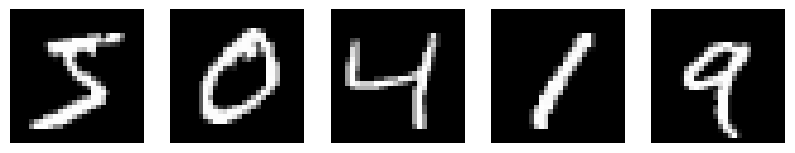

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 73s 37ms/step - accuracy: 0.9388 - loss: 0.2023 - val_accuracy: 0.9848 - val_loss: 0.0429
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.9780 - loss: 0.0755 - val_accuracy: 0.9874 - val_loss: 0.0333
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9834 - loss: 0.0569 - val_accuracy: 0.9905 - val_loss: 0.0278
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 34ms/step - accuracy: 0.9861 - loss: 0.0465 - val_accuracy: 0.9921 - val_loss: 0.0231
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 34ms/step - accuracy: 0.9886 - loss: 0.0375 - val_accuracy: 0.9900 - val_loss: 0.0327
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 33ms/step - accuracy: 0.9895 - loss: 0.0329 - val_accuracy: 0.9928 - val_loss: 0.0214
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9914 - loss: 0.0270 - val_accuracy: 0.9925 - val_loss: 0.0222
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 34ms/step - accuracy: 0.9922 -

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9925 - loss: 0.0218
Test Accuracy: 99.25%
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


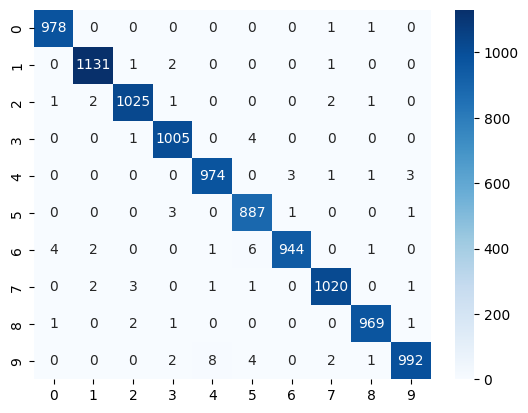

In [1]:
#Handwritten Digit Recognition
import argparse
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.utils import to_categorical

# ==========================================
# 1. LOAD DATASET
# ==========================================
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Visualizing Sample Digits
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i], cmap="gray")
    ax.axis("off")
plt.show()

# ==========================================
# 2. PREPROCESSING
# ==========================================
# Normalize
X_train, X_test = X_train / 255.0, X_test / 255.0

# Reshape for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# ==========================================
# 3. BUILD MODEL
# ==========================================
model = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(10, activation="softmax"),
    ]
)

model.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)

# ==========================================
# 4. MODEL TRAINING & SAVING
# ==========================================
model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))
model.save("models/mnist_model.h5")

# ==========================================
# 5. MODEL EVALUATION
# ==========================================
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Confusion Matrix
y_pred = model.predict(X_test).argmax(axis=1)
y_true = y_test.argmax(axis=1)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.show()


# ==========================================
# 6. INFERENCE FUNCTIONS
# ==========================================
def preprocess_image(image_path):
    """Load and preprocess an image for model prediction."""
    img = Image.open(image_path).convert("L")  # Convert to grayscale
    img = img.resize((28, 28))  # Resize to 28x28 pixels
    img = np.array(img) / 255.0  # Normalize pixel values
    img = img.reshape(1, 28, 28, 1)  # Reshape for model input
    return img


def predict_digit(image_path):
    """Predict the digit in the given image."""
    img = preprocess_image(image_path)
    prediction = model.predict(img).argmax()
    return prediction



1. **Tải và Khám phá Dữ liệu (Load Dataset)**:
   - Sử dụng tập dữ liệu MNIST nổi tiếng chứa 70.000 ảnh chữ số viết tay từ 0 đến 9 (kích thước 28x28 pixel).
   - Dữ liệu được chia sẵn thành tập huấn luyện (`X_train`, `y_train`) và tập kiểm thử (`X_test`, `y_test`).
   - Hiển thị 5 ảnh mẫu đầu tiên để kiểm tra trực quan.

2. **Tiền xử lý Dữ liệu (Preprocessing)**:
   - **Chuẩn hóa (Normalization)**: Chia giá trị pixel cho `255.0` để đưa khoảng giá trị từ `[0, 255]` về `[0.0, 1.0]`, giúp mô hình CNN hội tụ nhanh hơn.
   - **Thay đổi hình dạng (Reshape)**: Đổi kích thước ảnh từ `(28, 28)` thành `(28, 28, 1)` vì lớp tích chập 2D (Conv2D) yêu cầu dữ liệu đầu vào có 3 chiều (chiều rộng, chiều cao, số kênh màu - grayscale là 1).
   - **One-hot Encoding**: Chuyển nhãn số (ví dụ: `5`) thành vector nhị phân 10 chiều (ví dụ: `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`) bằng hàm `to_categorical` để phù hợp với hàm mất mát `categorical_crossentropy`.

3. **Xây dựng Mô hình (Build Model)**:
   - Sử dụng kiến trúc mạng tích chập (CNN) tuần tự `Sequential`:
     - **Conv2D + MaxPooling2D**: Trích xuất các đặc trưng không gian (cạnh, góc, hình dạng của chữ số).
     - **Flatten**: Làm phẳng ma trận đặc trưng thành vector 1 chiều.
     - **Dense (128 neurons)**: Lớp liên kết đầy đủ để phân loại.
     - **Dropout (0.5)**: Tắt ngẫu nhiên 50% neuron trong quá trình huấn luyện nhằm chống quá khớp (overfitting).
     - **Dense (10 neurons, Softmax)**: Lớp đầu ra dự đoán xác suất cho 10 lớp chữ số từ 0 đến 9.

4. **Huấn luyện Mô hình (Model Training)**:
   - Sử dụng bộ tối ưu hóa `Adam` và hàm mất mát `categorical_crossentropy`.
   - Huấn luyện qua 10 epochs (chu kỳ).



## Dựa trên kết quả chạy thực tế của mô hình bên trên, có các nhận xét sau:

* **Độ chính xác ấn tượng (High Accuracy)**:
  - Mô hình đạt độ chính xác trên tập kiểm thử (**Test Accuracy**) lên tới **99.25%**.
  - Giá trị mất mát trên tập kiểm thử (**Test Loss**) rất thấp, chỉ khoảng **0.0218**.

* **Tiến trình huấn luyện ổn định (Training Progress)**:
  - Qua 10 epochs, độ chính xác trên tập huấn luyện (`accuracy`) tăng đều từ **93.88%** (epoch 1) lên **99.40%** (epoch 10).
  - Độ chính xác trên tập validation (`val_accuracy`) cũng tăng và giữ ở mức rất cao (~**99.25%**).
  - Sự chênh lệch giữa `accuracy` (99.40%) và `val_accuracy` (99.25%) là cực kỳ nhỏ. Điều này chứng tỏ lớp **Dropout (0.5)** đã hoạt động rất hiệu quả trong việc ngăn chặn hiện tượng quá khớp (overfitting).

* **Phân tích Ma trận nhầm lẫn (Confusion Matrix)**:
  - Ma trận nhầm lẫn hiển thị các phần tử tập trung chủ yếu trên đường chéo chính, cho thấy mô hình phân loại chính xác hầu hết các chữ số.
  - Các lỗi nhầm lẫn xảy ra rất ít và thường nằm ở các cặp chữ số dễ gây nhầm lẫn khi viết tay (ví dụ: số 4 và số 9, hoặc số 7 và số 9).